In [1]:
# import all libraries
from wsidata import open_wsi
import lazyslide as zs
import matplotlib.pyplot as plt
import scanpy as sc
import pooch
import numpy as np
import marsilea as ma
import marsilea.plotter as mp
from scipy.stats import zscore
import pandas as pd
import os
from scipy.spatial import cKDTree
from wsidata import open_wsi
import anndata as ad

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


In [2]:
# loading in real data with zarr store
slide = "/mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.ndpi"
store = slide.replace(".ndpi", ".zarr")

wsi = open_wsi(
    slide,
    store=store,
    attach_images=False,  
    save_images=False   
)

version mismatch: detected: RasterFormatV02, requested: FormatV04
/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


In [ ]:
########################################
# Create a valid NGFF Zarr store for a WSI
# This prepares the slide for LazySlide analysis
########################################

# 1) Remove the old Zarr store (if it exists)
#    We delete the existing store because it may have invalid or outdated metadata.
rm -rf /mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.zarr

# 2) Download BioFormats2raw v0.9.4
#    BioFormats2raw converts proprietary slide formats (e.g., .ndpi) into OME-NGFF-compliant Zarr stores.
wget -O bioformats2raw-0.9.4.zip \
  https://github.com/glencoesoftware/bioformats2raw/releases/download/v0.9.4/bioformats2raw-0.9.4.zip

# 3) Unzip the converter
#    Extract the tool into a folder so we can run it locally.
unzip bioformats2raw-0.9.4.zip -d bioformats2raw_dist

# 4) Move into the tool’s directory
cd bioformats2raw_dist/bioformats2raw-0.9.4

# 5) Convert the NDPI WSI to Zarr
#    -p            → show progress while processing
#    --overwrite   → allow overwriting if a partial store exists
#    First path    → input NDPI slide
#    Second path   → output Zarr directory
./bin/bioformats2raw \
  -p \
  --overwrite \
  /mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.ndpi \
  /mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.zarr

# 6) Consolidate metadata
#    Creates a `.zmetadata` file at the Zarr root.
#    This is required for LazySlide and other NGFF-aware tools to load all resolutions efficiently.
python3 - <<EOF
import zarr
zarr.convenience.consolidate_metadata(
    "/mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.zarr"
)
print(".zmetadata created!")
EOF

# 7) Verify the Zarr structure
#    Expected contents: .zmetadata, .zattrs, .zgroup, images/, OME/, etc.
ls -la /mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.zarr

# 8) Confirm the presence of "multiscales" in metadata
#    The "multiscales" block defines the pyramid levels

In [ ]:
# Run once, feature extraction is saved on WSI object
HF_token = os.environ.get("HF_TOKEN", "hf_xxxxxxxxxxxxxxxxx")
zs.pp.find_tissues(wsi)
zs.pp.tile_tissues(wsi, 64)
zs.tl.feature_extraction(wsi, "h0-mini", token="hf_xxxxxxxxxxxxxxxxx")
zs.tl.feature_aggregation(wsi, feature_key="h0-mini")
wsi.write()

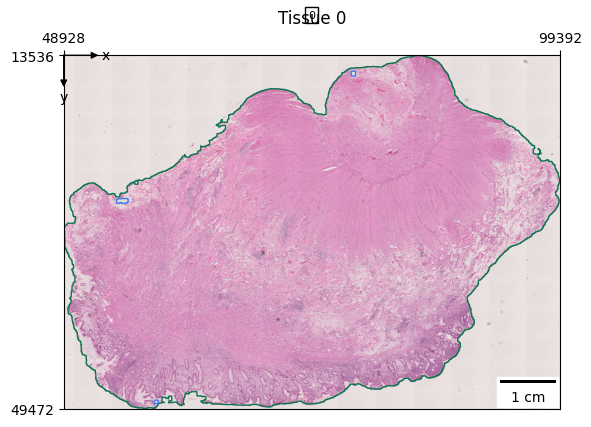

In [3]:
# check tissue segmentation
    # check for tissues in shapes container
wsi["tissues"]
zs.pl.tissue(wsi, tissue_id=0)

In [4]:
#cell segmentation
    #optimal size for cell segmentation
zs.pp.tile_tissues(wsi, 512, background_fraction=0.95, mpp=0.5, key_added="cell_tiles")
zs.seg.cells(wsi, tile_key="cell_tiles")
wsi.write()

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `cell_tiles` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


Output()

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `cells` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


In [ ]:
#zooming in on WSI image and cell segmentation
v = zs.pl.WSIViewer(wsi)
v.add_image()
v.add_polygons("cells", linewidth=0.1)
v.add_zoom(81000, 82000, 45500, 46500)
v.show()

WSI: /mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.ndpi
Reader: openslide
Dimensions: 64768×107520 (h×w), 8 Pyramids
Pixel physical size: 0.22075542506457096 MPP
SpatialData object, with associated Zarr store: /mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.zarr
├── Images
│     └── 'wsi_thumbnail': DataArray[cyx] (3, 725, 1204)
├── Shapes
│     ├── 'cell_tiles': GeoDataFrame shape: (1676, 3) (2D shapes)
│     ├── 'cells': GeoDataFrame shape: (275951, 1) (2D shapes)
│     ├── 'text_tiles': GeoDataFrame shape: (24662, 3) (2D shapes)
│     ├── 'text_tiles_big': GeoDataFrame shape: (356, 3) (2D shapes)
│     ├── 'tiles': GeoDataFrame shape: (506494, 3) (2D shapes)
│     └── 'tissues': GeoDataFrame shape: (2, 2) (2D shapes)
└── Tables
      ├── 'conch_text_tiles': AnnData (24662, 512)
      ├── 'conch_text_tiles_big': AnnData (356, 512)
      ├── 'conch_text_tiles_big_text_similarity': AnnData (356, 3)
      ├── 'conch_text_tiles_text_similarity': AnnData (24662, 7)
      ├── 'h0-mini_tiles': AnnData (506494, 1536)
      └── 'uni2_tiles': AnnData (506494, 1536)
with coordinate systems:
    ▸ 'global', with elements:
        wsi_thumbnail (Images), cell_tiles (Shapes), cells (Shapes), text_tiles (Shapes), text_tiles_big (Shapes), tiles (Shapes), tissues (Shapes)
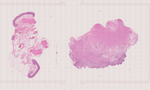

In [3]:
wsi

In [ ]:
#making text feature tiles (run once)
zs.pp.tile_tissues(wsi, 128, mpp=0.5, key_added="text_tiles")
zs.tl.feature_extraction(wsi, "conch", tile_key="text_tiles")
wsi.write()

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `conch_text_tiles_text_similarity` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


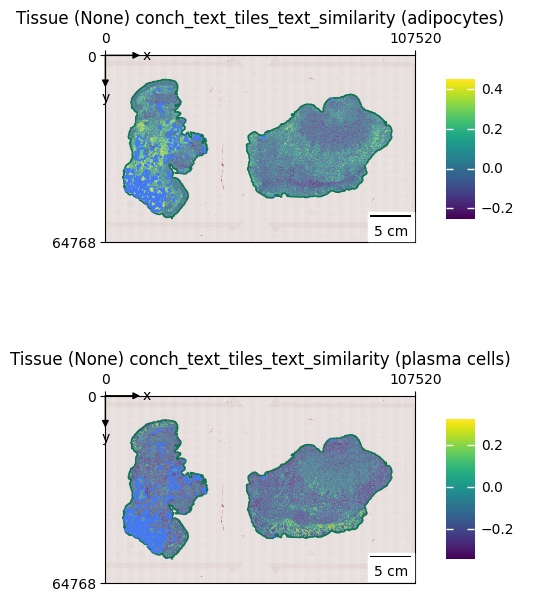

In [17]:
# Text Image Similarity 
terms = ["adipocytes", "plasma cells"]
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeddings,
    model="conch",
    tile_key="text_tiles",
    feature_key="conch_text_tiles",
    key_added="conch_text_tiles_similarity"
)
zs.pl.tiles(
    wsi,
    tile_key="text_tiles",
    feature_key="conch_text_tiles_text_similarity",
    style="heatmap",
    color=terms,
    ncols=1,          # one column → one plot per row
    hspace=0.4,       # more vertical space between rows
    alpha=0.7,
)

In [4]:
# Text Image Similarity 
terms = ["senescence"]
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeddings,
    model="conch",
    tile_key="text_tiles",
    feature_key="conch_text_tiles",
    key_added="conch_text_tiles_similarity"
)
fig = plt.figure(figsize=(12, 12))

zs.pl.tiles(
    wsi,
    tile_key="text_tiles",
    feature_key="conch_text_tiles_text_similarity",
    style="heatmap",
    cmap="rainbow",
    color=terms,
    ncols=1,          # one column → one plot per row
    hspace=0.4,       # more vertical space between rows
    alpha=0.7,
)

fig.savefig("senescence_TFE.svg", format="svg", dpi=300, bbox_inches="tight")


/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `conch_text_tiles_text_similarity` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


In [16]:
# Text Image Similarity 
terms = ["vascular"]
#, "epithelial", "inflammation", "stricture", "fibrosis"
#, "vein", "artery"
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeddings,
    model="conch",
    tile_key="text_tiles",
    feature_key="conch_text_tiles",
    key_added="conch_text_tiles_similarity"
)

fig = plt.figure(figsize=(12, 12))
zs.pl.tiles(
    wsi,
    tile_key="text_tiles",
    feature_key="conch_text_tiles_text_similarity",
    style="heatmap",
    cmap="rainbow",
    color=terms,
    ncols=1,          # one column → one plot per row
    hspace=0.4,       # more vertical space between rows
    alpha=0.7,
)

fig.savefig("vascular_TFE.svg", format="svg", dpi=300, bbox_inches="tight")

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `conch_text_tiles_text_similarity` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


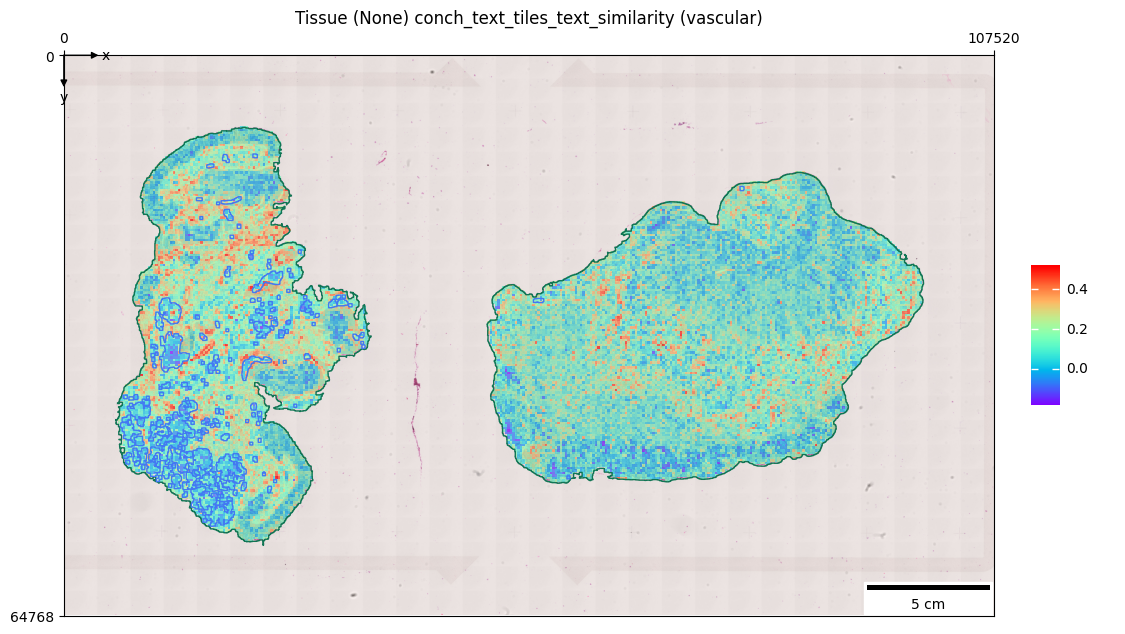

In [ ]:
# Text Image Similarity 
terms = ["vein"]
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeddings,
    model="conch",
    tile_key="text_tiles",
    feature_key="conch_text_tiles",
    key_added="conch_text_tiles_similarity"
)

fig = plt.figure(figsize=(12, 12))

zs.pl.tiles(
    wsi,
    tile_key="text_tiles",
    feature_key="conch_text_tiles_text_similarity",
    style="heatmap",
    cmap="rainbow",
    color=terms,
    ncols=1,          # one column → one plot per row
    hspace=0.4,       # more vertical space between rows
    alpha=0.7,
)

fig.savefig("vein_TFE.svg", format="svg", dpi=300, bbox_inches="tight")

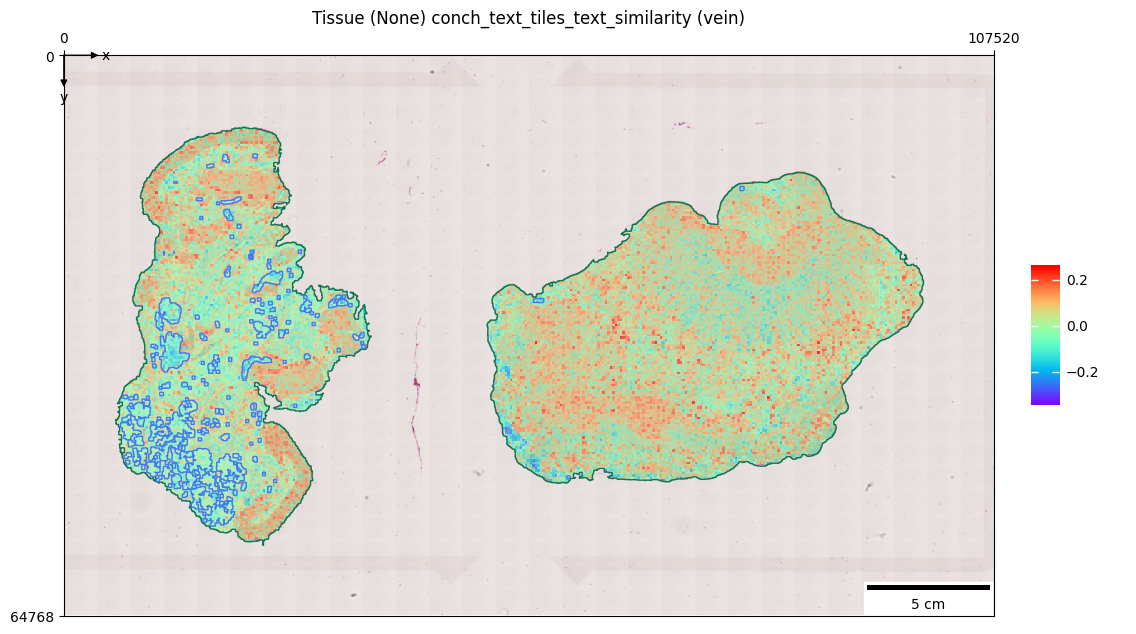

In [20]:
# Text Image Similarity 
terms = ["artery"]
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeddings,
    model="conch",
    tile_key="text_tiles",
    feature_key="conch_text_tiles",
    key_added="conch_text_tiles_similarity"
)

fig = plt.figure(figsize=(12, 12))

zs.pl.tiles(
    wsi,
    tile_key="text_tiles",
    feature_key="conch_text_tiles_text_similarity",
    style="heatmap",
    cmap="rainbow",
    color=terms,
    ncols=1,          # one column → one plot per row
    hspace=0.4,       # more vertical space between rows
    alpha=0.7,
)

fig.savefig("artery_TFE.svg", format="svg", dpi=300, bbox_inches="tight")

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `conch_text_tiles_text_similarity` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


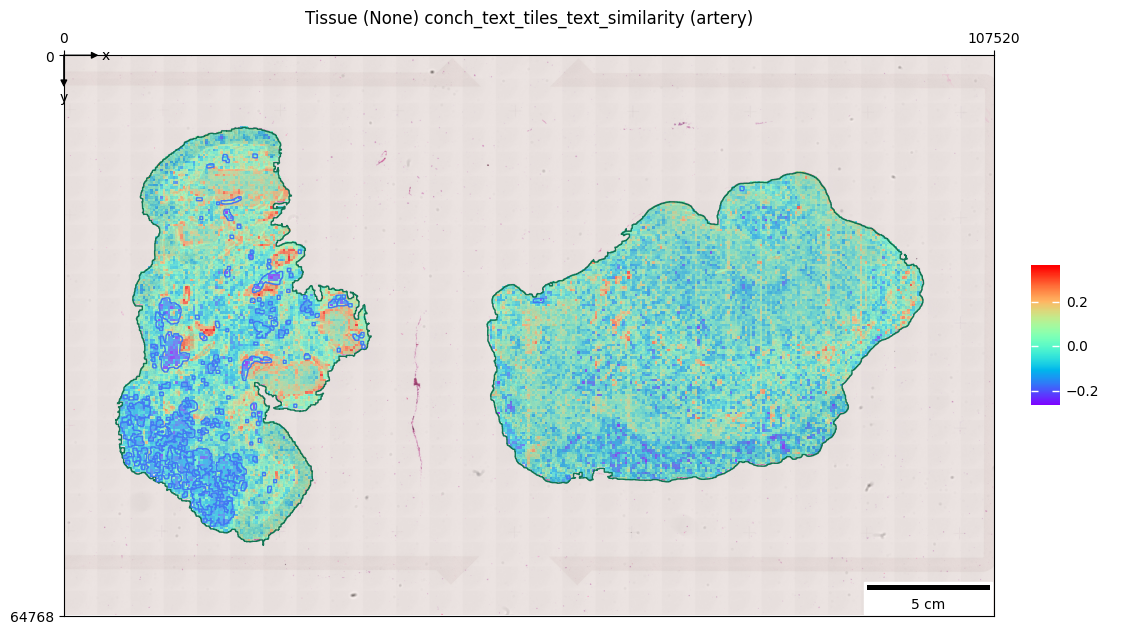

In [22]:
# Text Image Similarity 
terms = ["musclaris"]
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeddings,
    model="conch",
    tile_key="text_tiles",
    feature_key="conch_text_tiles",
    key_added="conch_text_tiles_similarity"
)
fig = plt.figure(figsize=(12, 12))

zs.pl.tiles(
    wsi,
    tile_key="text_tiles",
    feature_key="conch_text_tiles_text_similarity",
    style="heatmap",
    cmap="rainbow",
    color=terms,
    ncols=1,          # one column → one plot per row
    hspace=0.4,       # more vertical space between rows
    alpha=0.7,
)

fig.savefig("muscularis_TFE.svg", format="svg", dpi=300, bbox_inches="tight")

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `conch_text_tiles_text_similarity` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


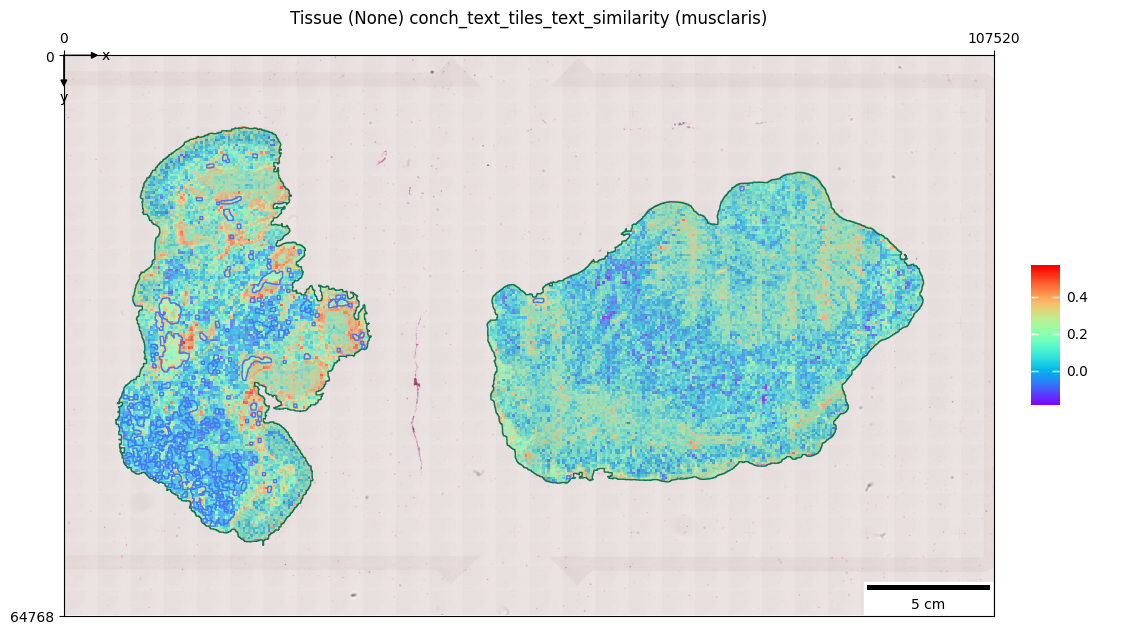

In [ ]:
# attempting using bigger tiles for text feature extraction
zs.pp.tile_tissues(
    wsi,
    tile_px=512,
    mpp=1.0,
    key_added="text_tiles_big"
)

zs.tl.feature_extraction(
    wsi,
    model="conch",
    tile_key="text_tiles_big",
    key_added="conch_text_tiles_big"
)
terms = ["mucosa", "submucosa", "muscularis"]
embeddings = zs.tl.text_embedding(terms, model="conch")
zs.tl.text_image_similarity(
    wsi,
    embeddings,
    model="conch",
    tile_key="text_tiles_big"
)

feature_key = "conch_text_tiles_big_text_similarity"

zs.pl.tiles(
    wsi,
    feature_key=feature_key,
    tile_key="text_tiles_big",
    color=terms,          # must match length = 3
    cmap="rainbow",
    show_image=False,
    tissue_id=0,
    ncols=3,              # 3 terms → 3 columns
    alpha=0.7,
)
zs.pl.tiles(
    wsi,
    feature_key=feature_key,
    tile_key="text_tiles_big",
    color=terms,
    cmap="rainbow",
    show_image=False,
    tissue_id=1,
    ncols=3,
    alpha=0.7,
)

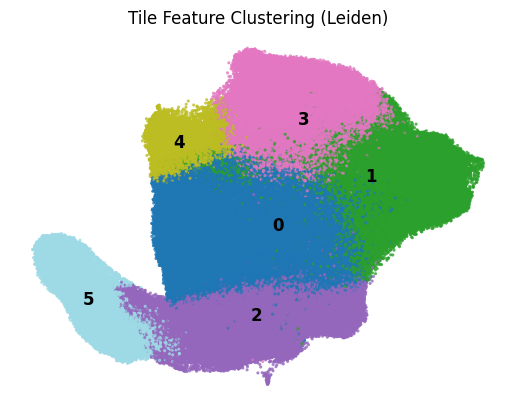

In [4]:
# examining feature space through UMAP
adata = wsi["h0-mini_tiles"]
sc.pp.scale(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, flavor="igraph", resolution=0.2)
sc.pl.umap(
    adata,
    color="leiden",
    title="Tile Feature Clustering (Leiden)",
    palette="tab20",  # Or try "Set2", "Paired", or a custom list
    size=20,          # Increase point size for better visibility
    alpha=0.8,        # Transparency of points
    frameon=False,    # Remove plot frame
    legend_loc='on data',  # Label clusters directly
    legend_fontsize=12,
    show=True,
    save="feature_extraction_umap.svg"
)
wsi.write(overwrite=True)

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: inv

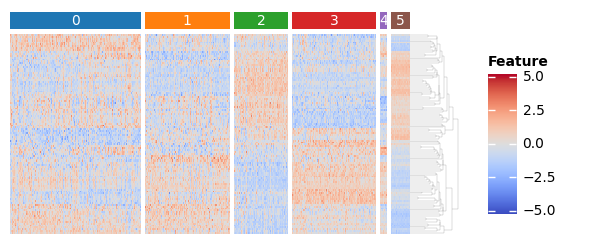

In [13]:
# Generating heatmap
sc.tl.rank_genes_groups(adata, groupby="leiden")

features = set()
for i in adata.obs["leiden"].unique():
    names = sc.get.rank_genes_groups_df(adata, i).names
    features.update(list(names[0:10]) + list(names[-10:]))
features = list(features)
key = "leiden"
h = ma.Heatmap(zscore(adata[:, features].X.T), height=2, width=4, label="Feature")
order = sorted(adata.obs[key].unique())
h.group_cols(adata.obs[key], order=order)
h.add_top(mp.Chunk(order, fill_colors=adata.uns[f"{key}_colors"], padding=2), pad=0.05)
h.add_dendrogram("right", method="average", linewidth=0.1)
h.add_legends()
h.render()

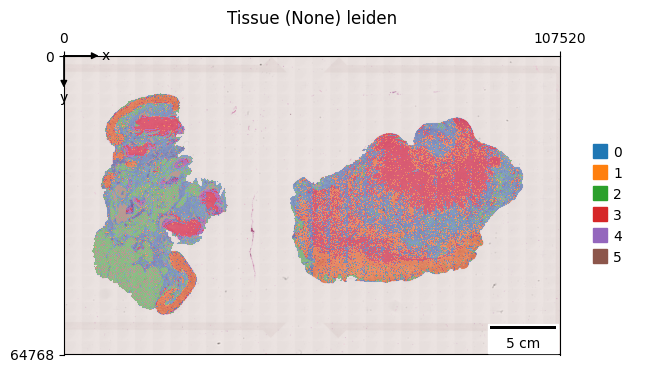

In [16]:
# 5 Domain Spatial Analysis
key = "leiden"
adata = wsi["h0-mini_tiles"]
clusters    = adata.obs["leiden"].cat.categories               # Index(['0','1','2',…], dtype=object)
colors      = adata.uns["leiden_colors"]                       # list/array of RGB(A) tuples
palette_map = dict(zip(clusters.astype(str), colors))         # {'0':(…), '1':(…), …}

zs.pl.tiles(
    wsi,
    feature_key="h0-mini_tiles",   # your tile‐level feature store
    tile_key="tiles",              # the GeoDataFrame with one polygon per tile
    color="leiden",
    palette=palette_map,           # now a dict, so palette['0'] works
    alpha=0.5,
    show_contours=False,
)

Output()

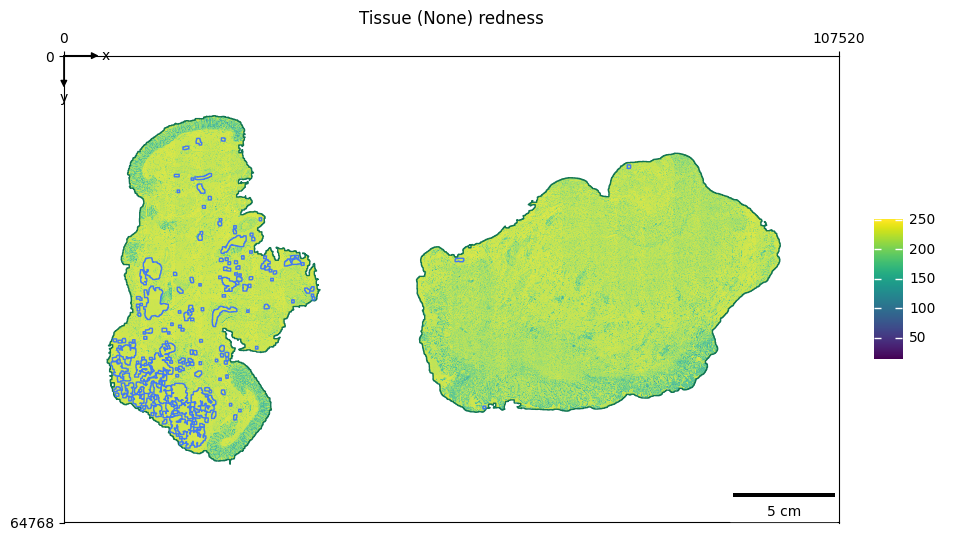

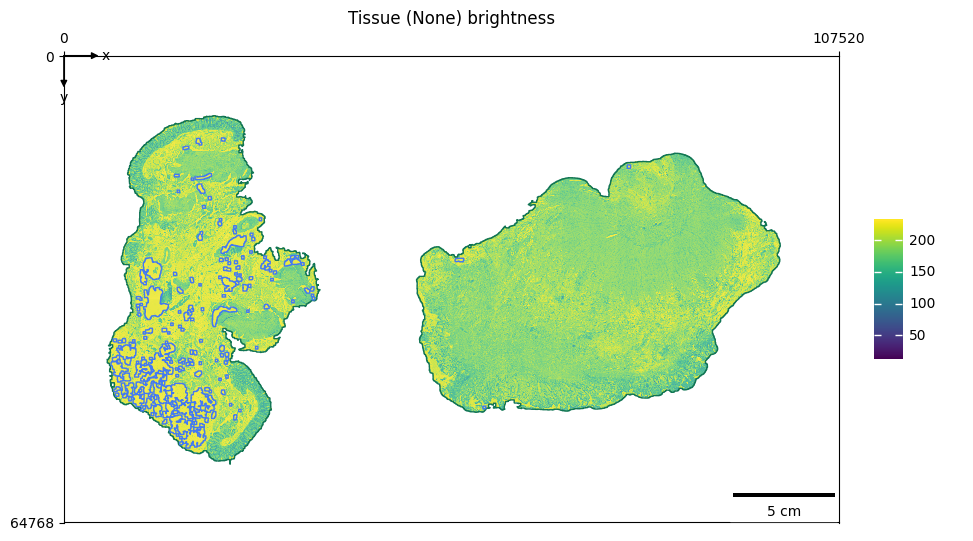

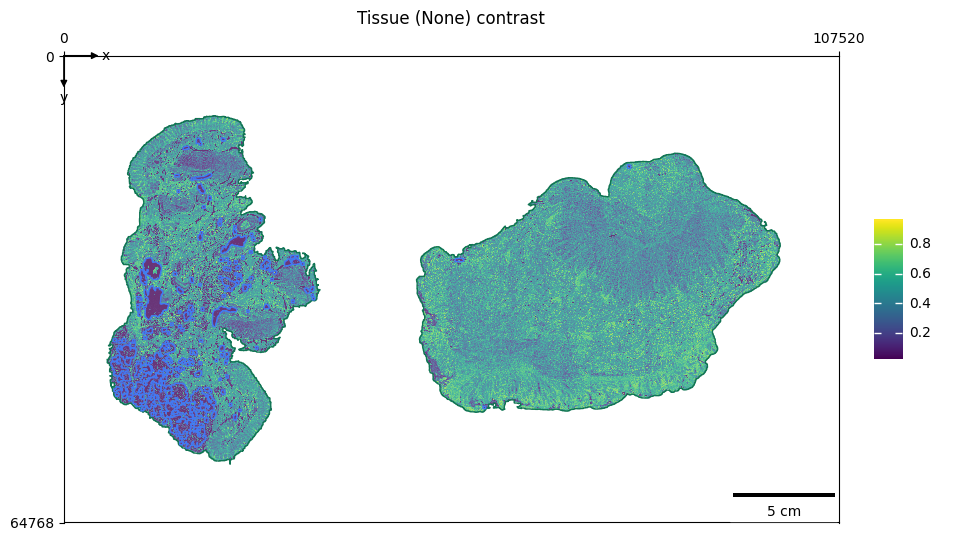

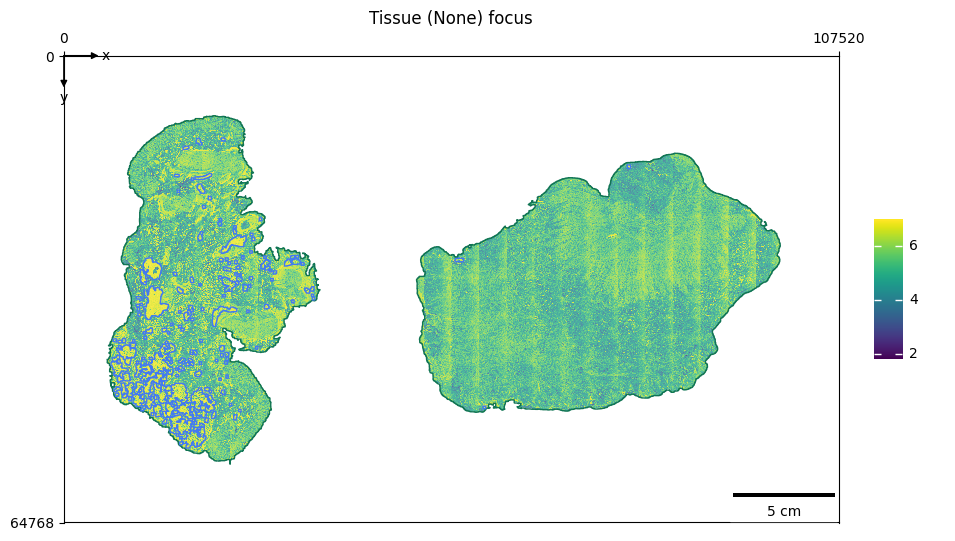

In [24]:
# Quality Control Through Lazyslide
zs.pp.score_tiles(
    wsi,
    scorers=["redness", "brightness", "contrast", "focus"],
    tile_key="tiles"  # use your tile key (e.g., "tiles", "text_tiles")
)

qc_metrics = ["redness", "brightness", "contrast", "focus"]

for metric in qc_metrics:
    fig, ax = plt.subplots(figsize=(10, 8))
    zs.pl.tiles(
        wsi,
        tile_key="tiles",
        color=metric,
        cmap="viridis",     # or any colormap you like
        alpha=0.8,
        show_image=False,
        style="heatmap",
        ax=ax
    )
    fig.savefig(f"{metric}_qc.svg", format="svg", bbox_inches="tight")

KeyError: "Could not find element with name 'tissue'"

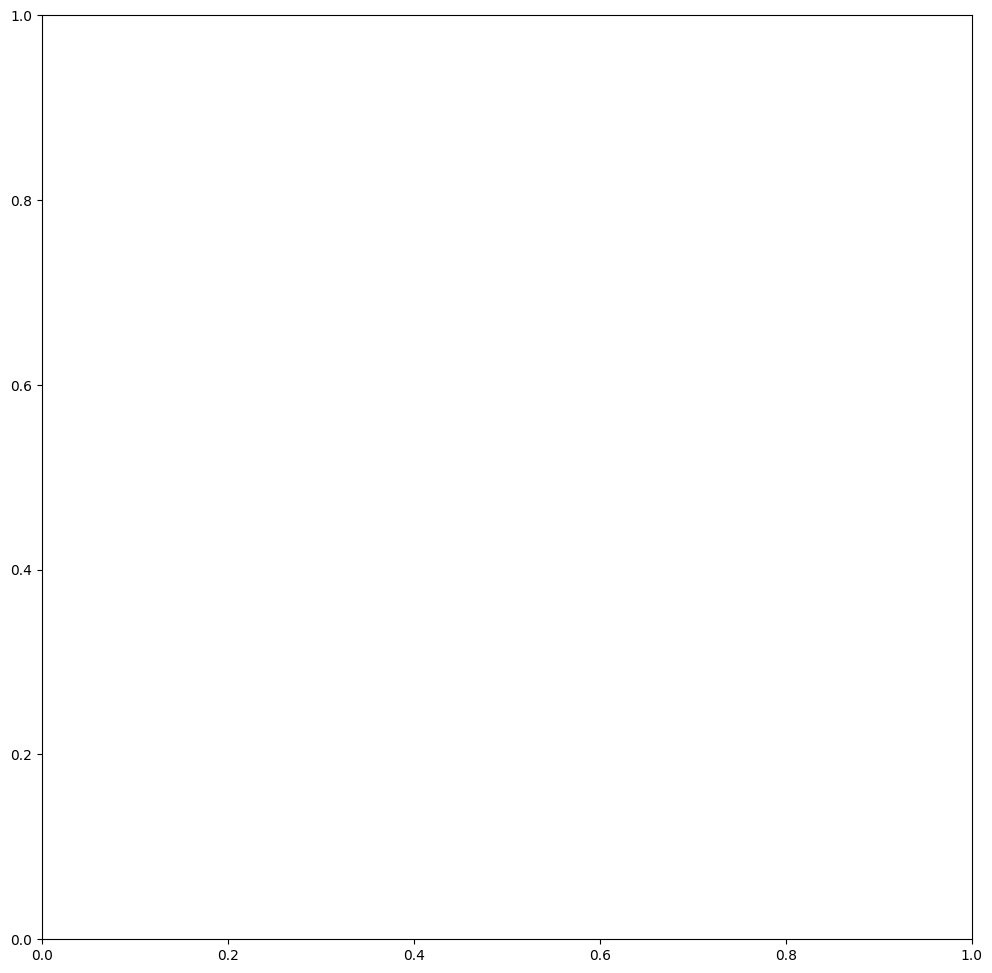

In [12]:
# 10 Domain Spatial Analysis 
adata = wsi["h0-mini_tiles"]
sc.tl.leiden(
    adata,
    flavor="igraph",
    resolution=0.5,
    directed=False,
    n_iterations=2
)

labels = sorted(adata.obs["leiden"].astype(str).unique())
colors = cm.tab20.colors[: len(labels)]
palette_map = dict(zip(labels, colors))


#zs.pl.tiles(
 #   wsi,
 #   feature_key="h0-mini_tiles",
 #   tile_key="tiles",
 #   color="leiden",
 #   palette=palette_map,
 #   alpha=0.5,
  #  show_contours=False
#)
fig = plt.figure(figsize=(12, 12))

zs.pl.tiles(
    wsi,
    feature_key="h0-mini_tiles",
    tile_key="tiles",
    color="leiden",
    palette=palette_map,
    alpha=0.8,
    show_contours=True,     
    mark_origin=False,
    scalebar=True,
    smooth=True,
    smooth_scale=2,
    linewidth=0.2,
    rasterized=False,
    title="Spatial Domains Identified via Feature Clustering",
    cmap="tab20",
    size=(12, 12),
    ax=plt.gca()
)

fig.savefig("lazy_tiles_zoomable.svg", format="svg", dpi=300, bbox_inches="tight")
plt.close(fig)

In [ ]:
# zero shot learning

In [31]:
#zs.tl.feature_extraction(
   # wsi,
  #  model="conch",
  #  tile_key="cell_tiles",
   # key_added="conch_512"
#)

classes = ["vascular", "vein", "artery", "epithelial", "inflammation", "stricture", "fibrosis"]
embeds = zs.tl.text_embedding(classes, model="conch")
zs.tl.text_image_similarity(
    wsi,
    text_embeddings=embeds,
    model="conch",                  # your model name
    tile_key="text_tiles",          # the shape‐group you want
    feature_key="conch_text_tiles", # the matching AnnData in wsi.tables
    key_added="conch_textsim_tiles" # whatever name you’d like for the new table
)

/mnt/data0/ikoluk/miniconda3/envs/wsi_env12/lib/python3.10/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `conch_text_tiles_text_similarity` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)


In [33]:
scores = zs.metrics.topk_score(wsi["conch_text_tiles_text_similarity"], agg_method="mean")
for c, s in zip(classes, scores / scores.sum()):
    print(f"{c}: {s:.2f}")


vascular: 0.20
vein: 0.10
artery: 0.14
epithelial: 0.18
inflammation: 0.12
stricture: 0.11
fibrosis: 0.14


In [ ]:
# Using scRNA to use RNALinker for each tissue singularly.

In [ ]:
zs.tl.feature_extraction(
    wsi,
    model="uni2",       # ← or "h0-mini" if you prefer
    tile_key="tiles",   # must match your GeoDataFrame name
)
wsi.write(overwrite=True, consolidate_metadata=True)

Output()

In [13]:
slide_feats = zs.tl.feature_aggregation(wsi, feature_key="uni2")
wsi.write(overwrite=True)

In [7]:
from wsidata import agg_wsi

df = pd.DataFrame({
    "sample_id": ["50006A-50006B"],
    "store": ["/mnt/data0/ikoluk/lazyslide/data/lazyslide_control/50006A-50006B.zarr"]
})

# Aggregate using store_col since we're using Zarr paths
agg_data = agg_wsi(df, feature_key="uni2", store_col="store", agg_key="agg_slide")
agg_data.obs["Tissue Sample Id"] = "50006A-50006B"
#agg_data.write_h5ad("agg_uni2_features_50006A-50006B.h5ad")

In [8]:
tpm_df = pd.read_csv("/mnt/data0/ikoluk/lazyslide/data/rsem.merged.gene_tpm.tsv", sep="\t", index_col=0)
tpm_df = tpm_df.T
print(tpm_df.index)

Index(['transcript_id(s)', 'R00837_S76', 'R00852_S1', 'R00854_S92',
       'R00858_S2', 'R00859_S86', 'R00860_S98', 'R00861_S83', 'R00873_S89',
       'R00879_S3',
       ...
       'SB362792_S87', 'SB362802_S88', 'SB363656_S89', 'SB363897_S90',
       'SB364835_S91', 'SB371140_S92', 'SB371603_S93', 'SB372034_S94',
       'SB387824_S95', 'SB388109_S96'],
      dtype='object', length=355)


In [9]:
rna = ad.AnnData(tpm_df)
rna.obs["Tissue Sample Id"] = rna.obs.index
wsi_features = agg_data.copy()


In [11]:
tile_feats = wsi.tables["uni2_tiles"]
print(tile_feats.obs.columns)
print(tpm_df.index.tolist())


Index(['tile_id', 'library_id'], dtype='object')
['transcript_id(s)', 'R00837_S76', 'R00852_S1', 'R00854_S92', 'R00858_S2', 'R00859_S86', 'R00860_S98', 'R00861_S83', 'R00873_S89', 'R00879_S3', 'R01154_S90', 'R01179_S97', 'R01189_S4', 'R01200_S91', 'R01207_S94', 'R01225_S93', 'R01228_S5', 'R01231_S81', 'R01248_S189', 'R01253_S6', 'R01256_S87', 'R01284_S7', 'R01289_S88', 'R01358_S84', 'R01361_S8', 'R01364_S77', 'R01382_S82', 'R01393_S9', 'R01396_S79', 'R01414_S10', 'R01473_S80', 'R01479_S85', 'R01523_S95', 'R01609_S78', 'R01824_S11', 'R01849_S12', 'R01873_S96', 'R01884_S13', 'R02893_S179', 'SB011401_S75', 'SB020484_S58', 'SB022456_S61', 'SB022460_S62', 'SB022635_S63', 'SB022690_S62', 'SB028380_S14', 'SB029943_S15', 'SB033853_S81', 'SB037071_S137', 'SB037102_S156', 'SB058567_S21', 'SB070177_S16', 'SB073872_S48', 'SB074142_S18', 'SB087665_S17', 'SB089760_S4', 'SB090103_S7', 'SB096649_S5', 'SB097897_S2', 'SB098264_S25', 'SB099085_S31', 'SB101510_S1', 'SB103448_S18', 'SB103938_S19', 'SB10473

In [37]:

tile_feats.obs["tissue"] = wsi.shapes["tiles"].align(wsi.shapes["tissues"])


ModuleNotFoundError: No module named 'lazyslide.utils'